In [47]:
import pandas as pd
import numpy as np
import plotly.express as px
from sklearn.model_selection import train_test_split

# Question 6

In [5]:
df = pd.read_csv('heart.csv')
X = df.drop('target', axis=1)
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=200, random_state=42)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((200, 13), (103, 13), (200,), (103,))

In [40]:
from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train, y_train)
np.set_printoptions(precision=6, suppress=True)
print(logreg.coef_)

[[ 0.022035 -1.092095  0.888202 -0.008555 -0.000855  0.1458    0.498253
   0.018525 -0.858136 -0.480381  0.752875 -1.372233 -1.217811]]


In [36]:
from sklearn.metrics import accuracy_score
1 - accuracy_score(y_test, logreg.predict(X_test))

0.19417475728155342

In [38]:
from sklearn.model_selection import cross_val_score
1 - cross_val_score(logreg, X_train, y_train, cv=5).mean()

np.float64(0.15000000000000002)

# Question 7

In [71]:
def error_estimate(cols):
    logreg = LogisticRegression(max_iter=1000, penalty=None)
    return 1 - cross_val_score(logreg, X_train[cols], y_train, cv=5).mean()

def SFS(k):
    S = []
    cols = list(X_train.columns)
    for _ in range(k):
        S.append(cols.pop(np.argmin([error_estimate(S + [col]) for col in cols])))
    return S

In [79]:
cv_errors = []
test_errors = []
feature_sets = []

for k in range(1, 14):
    S = SFS(k)
    feature_sets.append(S)

    # Cross-validation error on training set
    cv_errors.append(error_estimate(S))

    # Train model on training set, evaluate on test set
    logreg = LogisticRegression(max_iter=1000, penalty=None)
    logreg.fit(X_train[S], y_train)
    test_error = 1 - accuracy_score(y_test, logreg.predict(X_test[S]))
    test_errors.append(test_error)

# Plot both
import plotly.graph_objects as go

fig = go.Figure()
fig.add_trace(go.Scatter(x=list(range(1, 14)), y=cv_errors, mode='lines+markers', name='CV Error'))
fig.add_trace(go.Scatter(x=list(range(1, 14)), y=test_errors, mode='lines+markers', name='Test Error'))

fig.update_layout(title='Stepwise Feature Selection',
                  xaxis_title='Number of Selected Features (k)',
                  yaxis_title='Error Rate',
                  legend_title='Error Type')
fig.show()


c:\Users\issac\miniforge3\envs\dsc80\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning:

lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression

c:\Users\issac\miniforge3\envs\dsc80\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning:

lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression

c:\Users\issac\min

Selected features: ['cp', 'age']


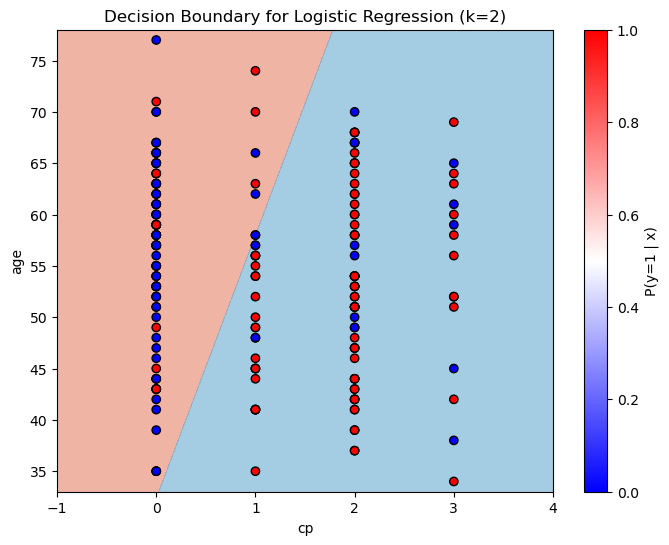

In [80]:
import matplotlib.pyplot as plt
import numpy as np

# Step 1: Get the two selected features
features = SFS(2)
print("Selected features:", features)

# Step 2: Fit logistic regression using just these two
model = LogisticRegression(max_iter=1000, penalty=None)
model.fit(X_train[features], y_train)

# Step 3: Plot the training points
x_min, x_max = X_train[features[0]].min() - 1, X_train[features[0]].max() + 1
y_min, y_max = X_train[features[1]].min() - 1, X_train[features[1]].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500),
                     np.linspace(y_min, y_max, 500))

grid = pd.DataFrame({features[0]: xx.ravel(), features[1]: yy.ravel()})
probs = model.predict_proba(grid)[:, 1].reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, probs, levels=[0, 0.5, 1], cmap="RdBu", alpha=0.6)
plt.scatter(X_train[features[0]], X_train[features[1]], c=y_train, cmap="bwr", edgecolors="k")
plt.xlabel(features[0])
plt.ylabel(features[1])
plt.title("Decision Boundary for Logistic Regression (k=2)")
plt.colorbar(label="P(y=1 | x)")
plt.show()
